# Consolidação comparativa — ARIMAX vs. LightGBM vs. Prophet

**Projeto:** IPCA sob pressão externa
**Autor:** Gabriel Abreu
**Orientadora:** Bruna Nogueira Rezende

Este notebook consolida os resultados dos três modelos para avaliar as hipóteses do estudo:

| Hipótese | Critério principal |
|----------|--------------------|
| **H1** — modelos de ML têm desempenho distinto do ARIMAX | DM par-a-par entre modelos por horizonte |
| **H2** — vantagem do ML é maior em alta volatilidade cambial | Métricas condicionais por regime |
| **H3** — CPI EUA agrega ganho preditivo significativo | DM M1 (só câmbio) vs M2 (câmbio + CPI), por modelo |

## Estrutura

1. Carregamento das previsões dos três modelos
2. Tabela consolidada de métricas (MAE, RMSE, MASE) por horizonte
3. Métricas por subperíodo (choque vs. acomodação) — H2 indireto
4. Métricas por regime de volatilidade — H2
5. Testes Diebold-Mariano par-a-par — H1
6. Síntese de H3 (consolidado dos 3 modelos)
7. Visualizações comparativas
8. Exportação do consolidado


## 0. Dependências

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy            import stats

np.random.seed(42)
plt.rcParams['figure.dpi']        = 130
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

print('Dependências carregadas.')

Dependências carregadas.


## 1. Carregamento das previsões

Lê os CSVs exportados por cada notebook de modelo. Padroniza para estrutura
comum: `model`, `spec`, `horizon`, `date`, `actual`, `predicted`.

Específico por modelo:
- **ARIMAX**: `arimax_preds_{spec}_h{h}.csv` com specs `M1_fx`, `M2_fx_cpi2`, `M2_fx_cpi3`
- **LightGBM**: `lgbm_preds_{spec}_h{h}.csv` com specs `M0_baseline_fx`, `M0_baseline`, `M1_fx`, `M2_fx_cpi`
- **Prophet**: `prophet_preds_{spec}_h{h}.csv` com specs `M1_fx`, `M2_fx_cpi2`, `M2_fx_cpi3`


In [2]:
# -- ASSUMPTION: notebook executado a partir da raiz do projeto (BR_INFLATION_FORECASTING)
# Os CSVs ficam nas subpastas arimax/, lightgbm/, prophet/
ROOT = Path.cwd()

PATHS = {
    'ARIMAX':   ROOT / 'arimax',
    'LightGBM': ROOT / 'lightgbm',
    'Prophet':  ROOT / 'prophet',
}

PREFIXES = {
    'ARIMAX':   'arimax_preds',
    'LightGBM': 'lgbm_preds',
    'Prophet':  'prophet_preds',
}


def load_model_preds(model_name):
    """Carrega todas as previsões de um modelo em um único DataFrame longo."""
    path   = PATHS[model_name]
    prefix = PREFIXES[model_name]

    files = sorted(path.glob(f'{prefix}_*.csv'))
    if not files:
        raise FileNotFoundError(f'Nenhum CSV encontrado em {path} com prefixo {prefix}')

    frames = []
    for f in files:
        # parse {prefix}_{spec}_h{h}.csv
        stem  = f.stem
        rest  = stem.replace(f'{prefix}_', '')
        parts = rest.rsplit('_h', 1)
        spec, h = parts[0], int(parts[1])

        d = pd.read_csv(f, parse_dates=['date'])
        d['model']   = model_name
        d['spec']    = spec
        d['horizon'] = h
        frames.append(d)

    return pd.concat(frames, ignore_index=True)


preds_all = pd.concat([load_model_preds(m) for m in PATHS], ignore_index=True)
preds_all = preds_all.dropna(subset=['predicted'])

print('Shape:', preds_all.shape)
print('\nContagem por (model, spec, horizon):')
print(preds_all.groupby(['model', 'spec', 'horizon']).size().to_string())

Shape: (1680, 6)

Contagem por (model, spec, horizon):
model     spec            horizon
ARIMAX    M1_fx           1          60
                          2          60
                          3          60
          M2_fx_cpi2      1          60
                          2          60
          M2_fx_cpi3      1          60
                          2          60
                          3          60
LightGBM  M0_baseline     1          60
                          2          60
                          3          60
          M0_baseline_fx  1          60
                          2          60
                          3          60
          M1_fx           1          60
                          2          60
                          3          60
          M2_fx_cpi       1          60
                          2          60
                          3          60
Prophet   M1_fx           1          60
                          2          60
                          3    

## 2. Spec principal de cada modelo (para H1)

Para a comparação inter-modelos (H1), usamos a especificação **com CPI** de cada
modelo. Para `h=3`, o CPI lag 2 fica indisponível — usa-se CPI lag 3 (ARIMAX e
Prophet) ou a spec equivalente do LightGBM.


In [3]:
def main_spec(model, horizon):
    """Retorna a spec principal de cada modelo para H1 (com CPI)."""
    if model == 'ARIMAX':
        return 'M2_fx_cpi2' if horizon <= 2 else 'M2_fx_cpi3'
    if model == 'Prophet':
        return 'M2_fx_cpi2' if horizon <= 2 else 'M2_fx_cpi3'
    if model == 'LightGBM':
        return 'M2_fx_cpi'
    raise ValueError(model)


def fx_only_spec(model, horizon):
    """Retorna a spec só com câmbio (para H3)."""
    if model == 'LightGBM':
        return 'M1_fx'
    return 'M1_fx'  # ARIMAX e Prophet usam o mesmo nome


def get_preds(model, horizon, spec=None):
    """Recupera DataFrame de previsões para uma combinação modelo/horizonte/spec."""
    if spec is None:
        spec = main_spec(model, horizon)
    mask = (
        (preds_all['model']   == model) &
        (preds_all['horizon'] == horizon) &
        (preds_all['spec']    == spec)
    )
    return preds_all[mask].sort_values('date').reset_index(drop=True)


# Verifica que todas as combinações principais existem
print('Verificação de specs principais:')
for model in PATHS:
    for h in [1, 2, 3]:
        d = get_preds(model, h)
        print(f'  {model:10} h={h} spec={main_spec(model, h):12} → {len(d):3d} obs')

Verificação de specs principais:
  ARIMAX     h=1 spec=M2_fx_cpi2   →  60 obs
  ARIMAX     h=2 spec=M2_fx_cpi2   →  60 obs
  ARIMAX     h=3 spec=M2_fx_cpi3   →  60 obs
  LightGBM   h=1 spec=M2_fx_cpi    →  60 obs
  LightGBM   h=2 spec=M2_fx_cpi    →  60 obs
  LightGBM   h=3 spec=M2_fx_cpi    →  60 obs
  Prophet    h=1 spec=M2_fx_cpi2   →  60 obs
  Prophet    h=2 spec=M2_fx_cpi2   →  60 obs
  Prophet    h=3 spec=M2_fx_cpi3   →  60 obs


## 3. Tabela consolidada de métricas por horizonte

In [4]:
# Carrega ipca de treino para MASE (consistente com cada notebook individual)
# Usa o final_df_with_lags.csv (mesma fonte que os 3 notebooks)
df_full = pd.read_csv(ROOT / 'final_df_with_lags.csv', parse_dates=['data'], index_col='data')
TRAIN_END  = '2019-12-01'
train_ipca = df_full[df_full.index <= TRAIN_END]['ipca_pct'].values
naive_mae  = np.mean(np.abs(np.diff(train_ipca)))

print(f'Naive MAE (treino, para MASE): {naive_mae:.4f}')


def compute_metrics(d):
    if len(d) == 0:
        return {'MAE': np.nan, 'RMSE': np.nan, 'MASE': np.nan, 'n': 0}
    act, pred = d['actual'].values, d['predicted'].values
    mae       = mean_absolute_error(act, pred)
    return {
        'MAE':  mae,
        'RMSE': np.sqrt(mean_squared_error(act, pred)),
        'MASE': mae / naive_mae,
        'n':    len(d),
    }


rows = []
for model in PATHS:
    for h in [1, 2, 3]:
        d = get_preds(model, h)
        m = compute_metrics(d)
        rows.append({'model': model, 'horizon': h, 'spec': main_spec(model, h), **m})

metrics_df = pd.DataFrame(rows).sort_values(['horizon', 'MAE'])
print('\nMétricas consolidadas — spec principal de cada modelo (com CPI):')
print(metrics_df.round(4).to_string(index=False))

Naive MAE (treino, para MASE): 0.2321

Métricas consolidadas — spec principal de cada modelo (com CPI):
   model  horizon       spec    MAE   RMSE   MASE  n
 Prophet        1 M2_fx_cpi2 0.2903 0.3767 1.2507 60
  ARIMAX        1 M2_fx_cpi2 0.2920 0.3804 1.2579 60
LightGBM        1  M2_fx_cpi 0.3118 0.4106 1.3433 60
 Prophet        2 M2_fx_cpi2 0.2890 0.3755 1.2449 60
LightGBM        2  M2_fx_cpi 0.3079 0.4084 1.3262 60
  ARIMAX        2 M2_fx_cpi2 0.3187 0.4298 1.3729 60
 Prophet        3 M2_fx_cpi3 0.2902 0.3762 1.2500 60
LightGBM        3  M2_fx_cpi 0.3168 0.4106 1.3648 60
  ARIMAX        3 M2_fx_cpi3 0.3386 0.4597 1.4587 60


### 3.1. Mesma tabela em formato pivot (mais fácil para o TCC)

In [5]:
for metric in ['MAE', 'RMSE', 'MASE']:
    piv = metrics_df.pivot(index='model', columns='horizon', values=metric)
    piv.columns = [f'h={h}' for h in piv.columns]
    print(f'\n── {metric} ──')
    print(piv.round(4).to_string())


── MAE ──
             h=1     h=2     h=3
model                           
ARIMAX    0.2920  0.3187  0.3386
LightGBM  0.3118  0.3079  0.3168
Prophet   0.2903  0.2890  0.2902

── RMSE ──
             h=1     h=2     h=3
model                           
ARIMAX    0.3804  0.4298  0.4597
LightGBM  0.4106  0.4084  0.4106
Prophet   0.3767  0.3755  0.3762

── MASE ──
             h=1     h=2     h=3
model                           
ARIMAX    1.2579  1.3729  1.4587
LightGBM  1.3433  1.3262  1.3648
Prophet   1.2507  1.2449  1.2500


## 4. Métricas por subperíodo (choque agudo 2020-21 vs. acomodação 2022-24)

In [6]:
SUBPERIODS = [
    ('choque_2020_2021',  '2020-01-01', '2021-12-31'),
    ('acomodacao_22_24',  '2022-01-01', '2024-12-31'),
]

rows_sub = []
for model in PATHS:
    for h in [1, 2, 3]:
        d = get_preds(model, h)
        if d.empty:
            continue
        for label, start, end in SUBPERIODS:
            mask = (d['date'] >= start) & (d['date'] <= end)
            d_sub = d[mask]
            if len(d_sub) < 3:
                continue
            m = compute_metrics(d_sub)
            rows_sub.append({
                'model':     model,
                'horizon':   h,
                'subperiod': label,
                **m,
            })

subperiod_df = pd.DataFrame(rows_sub).sort_values(['horizon', 'subperiod', 'MAE'])
print('Métricas por subperíodo:')
print(subperiod_df.round(4).to_string(index=False))

Métricas por subperíodo:
   model  horizon        subperiod    MAE   RMSE   MASE  n
 Prophet        1 acomodacao_22_24 0.2322 0.3404 1.0002 36
  ARIMAX        1 acomodacao_22_24 0.2470 0.3561 1.0639 36
LightGBM        1 acomodacao_22_24 0.2864 0.3947 1.2338 36
LightGBM        1 choque_2020_2021 0.3499 0.4332 1.5074 24
  ARIMAX        1 choque_2020_2021 0.3596 0.4141 1.5490 24
 Prophet        1 choque_2020_2021 0.3775 0.4254 1.6264 24
 Prophet        2 acomodacao_22_24 0.2302 0.3377 0.9916 36
LightGBM        2 acomodacao_22_24 0.2718 0.3814 1.1709 36
  ARIMAX        2 acomodacao_22_24 0.2740 0.4119 1.1804 36
LightGBM        2 choque_2020_2021 0.3619 0.4459 1.5592 24
 Prophet        2 choque_2020_2021 0.3772 0.4259 1.6250 24
  ARIMAX        2 choque_2020_2021 0.3858 0.4554 1.6618 24
 Prophet        3 acomodacao_22_24 0.2333 0.3404 1.0050 36
LightGBM        3 acomodacao_22_24 0.2718 0.3749 1.1709 36
  ARIMAX        3 acomodacao_22_24 0.3000 0.4428 1.2922 36
 Prophet        3 choque_2020_2

### 4.1. Razão de MAE (choque / acomodação) por modelo

In [7]:
ratio = (
    subperiod_df
    .pivot_table(index=['model', 'horizon'], columns='subperiod', values='MAE')
    .assign(ratio_choque_acomodacao=lambda x: x['choque_2020_2021'] / x['acomodacao_22_24'])
    .round(4)
)
print('Razão MAE choque/acomodação (>1 = pior na crise):')
print(ratio.to_string())

Razão MAE choque/acomodação (>1 = pior na crise):
subperiod         acomodacao_22_24  choque_2020_2021  ratio_choque_acomodacao
model    horizon                                                             
ARIMAX   1                  0.2470            0.3596                   1.4560
         2                  0.2740            0.3858                   1.4079
         3                  0.3000            0.3966                   1.3221
LightGBM 1                  0.2864            0.3499                   1.2218
         2                  0.2718            0.3619                   1.3315
         3                  0.2718            0.3844                   1.4141
Prophet  1                  0.2322            0.3775                   1.6261
         2                  0.2302            0.3772                   1.6388
         3                  0.2333            0.3755                   1.6095


## 5. Métricas por regime de volatilidade cambial — H2

Volatilidade do câmbio: desvio padrão móvel 12m do `usd_brl_pct`. Limiar: mediana
sobre janela de treino (fixo para o teste). Mesmo procedimento dos 3 notebooks
individuais.


In [8]:
df_full['vol_cambio_12m'] = df_full['usd_brl_pct'].rolling(12).std()
vol_threshold = df_full[df_full.index <= TRAIN_END]['vol_cambio_12m'].median()
df_full['regime_vol'] = np.where(df_full['vol_cambio_12m'] > vol_threshold, 'alta', 'baixa')

print(f'Limiar de volatilidade (mediana treino): {vol_threshold:.4f}')
print('\nDistribuição no teste:')
print(df_full[df_full.index > TRAIN_END]['regime_vol'].value_counts())

Limiar de volatilidade (mediana treino): 4.0499

Distribuição no teste:
regime_vol
alta     33
baixa    27
Name: count, dtype: int64


In [9]:
regime_lookup = df_full['regime_vol']

rows_reg = []
for model in PATHS:
    for h in [1, 2, 3]:
        d = get_preds(model, h).copy()
        if d.empty:
            continue
        d['regime'] = d['date'].map(regime_lookup)

        for regime in ['alta', 'baixa']:
            d_reg = d[d['regime'] == regime]
            if len(d_reg) < 3:
                continue
            m = compute_metrics(d_reg)
            rows_reg.append({
                'model':   model,
                'horizon': h,
                'regime':  regime,
                **m,
            })

regime_df = pd.DataFrame(rows_reg).sort_values(['horizon', 'regime', 'MAE'])
print('Métricas por regime de volatilidade:')
print(regime_df.round(4).to_string(index=False))

Métricas por regime de volatilidade:
   model  horizon regime    MAE   RMSE   MASE  n
LightGBM        1   alta 0.3577 0.4585 1.5410 33
  ARIMAX        1   alta 0.3587 0.4401 1.5452 33
 Prophet        1   alta 0.3652 0.4443 1.5731 33
 Prophet        1  baixa 0.1988 0.2721 0.8565 27
  ARIMAX        1  baixa 0.2105 0.2912 0.9068 27
LightGBM        1  baixa 0.2557 0.3429 1.1016 27
LightGBM        2   alta 0.3607 0.4588 1.5537 33
 Prophet        2   alta 0.3630 0.4422 1.5639 33
  ARIMAX        2   alta 0.4013 0.4914 1.7286 33
 Prophet        2  baixa 0.1985 0.2726 0.8551 27
  ARIMAX        2  baixa 0.2178 0.3398 0.9383 27
LightGBM        2  baixa 0.2433 0.3367 1.0482 27
 Prophet        3   alta 0.3677 0.4454 1.5838 33
LightGBM        3   alta 0.3850 0.4705 1.6586 33
  ARIMAX        3   alta 0.4218 0.5377 1.8172 33
 Prophet        3  baixa 0.1954 0.2683 0.8420 27
LightGBM        3  baixa 0.2335 0.3225 1.0059 27
  ARIMAX        3  baixa 0.2369 0.3409 1.0206 27


### 5.1. Razão MAE (alta / baixa volatilidade) — teste central de H2

In [10]:
h2_ratio = (
    regime_df
    .pivot_table(index=['model', 'horizon'], columns='regime', values='MAE')
    .assign(ratio_alta_baixa=lambda x: x['alta'] / x['baixa'])
    .round(4)
)
print('Razão MAE alta/baixa volatilidade (>1 = pior em volatilidade alta):')
print(h2_ratio.to_string())
print('''
Interpretação para H2:
- Se razão LightGBM < razão ARIMAX em alta volatilidade → ML tem vantagem (suporta H2)
- Se razões similares → H2 não suportada
''')

Razão MAE alta/baixa volatilidade (>1 = pior em volatilidade alta):
regime              alta   baixa  ratio_alta_baixa
model    horizon                                  
ARIMAX   1        0.3587  0.2105            1.7041
         2        0.4013  0.2178            1.8423
         3        0.4218  0.2369            1.7805
LightGBM 1        0.3577  0.2557            1.3989
         2        0.3607  0.2433            1.4822
         3        0.3850  0.2335            1.6489
Prophet  1        0.3652  0.1988            1.8367
         2        0.3630  0.1985            1.8289
         3        0.3677  0.1954            1.8811

Interpretação para H2:
- Se razão LightGBM < razão ARIMAX em alta volatilidade → ML tem vantagem (suporta H2)
- Se razões similares → H2 não suportada



## 6. Diebold-Mariano par-a-par entre modelos — H1

Testa se há diferença estatística de acurácia entre cada par de modelos, por
horizonte. Spec usada: a principal de cada modelo (com CPI).

`DM > 0` → modelo 1 tem erro quadrático maior (pior) que modelo 2.


In [11]:
def diebold_mariano(e1, e2, h=1):
    """DM (1995) com HAC Newey-West (lags = h-1)."""
    d      = e1**2 - e2**2
    n      = len(d)
    d_mean = np.mean(d)

    gamma0 = np.var(d, ddof=1)
    gammas = [np.cov(d[k:], d[:-k])[0, 1] for k in range(1, h)] if h > 1 else []
    var_d  = max((gamma0 + 2 * sum(gammas)) / n, 1e-10)

    dm_stat = d_mean / np.sqrt(var_d)
    p_value = 2 * (1 - stats.norm.cdf(abs(dm_stat)))
    return {'dm_stat': dm_stat, 'p_value': p_value}


def aligned_errors(model_a, model_b, horizon):
    """Alinha as previsões dos dois modelos por data e retorna erros pareados."""
    a = get_preds(model_a, horizon)[['date', 'actual', 'predicted']]
    b = get_preds(model_b, horizon)[['date', 'actual', 'predicted']]
    merged = a.merge(b, on='date', how='inner', suffixes=('_a', '_b'))
    if merged.empty:
        return None, None
    e_a = (merged['actual_a'] - merged['predicted_a']).values
    e_b = (merged['actual_b'] - merged['predicted_b']).values
    return e_a, e_b


from itertools import combinations

dm_pairs = []
models_list = list(PATHS.keys())

print('Teste DM par-a-par entre modelos (spec principal):')
print('DM > 0 → modelo_a pior | p < 0.05 → rejeita H0 de acurácia equivalente')
print('-' * 85)

for h in [1, 2, 3]:
    print(f'\nHorizonte h={h}:')
    for m_a, m_b in combinations(models_list, 2):
        e_a, e_b = aligned_errors(m_a, m_b, h)
        if e_a is None or len(e_a) < 5:
            continue
        dm  = diebold_mariano(e_a, e_b, h=h)
        sig = '✓ SIGNIFICATIVO (5%)' if dm['p_value'] < 0.05 else '✗ não significativo'
        print(f'  {m_a:10} vs {m_b:10}: DM={dm["dm_stat"]:+.4f}, p={dm["p_value"]:.4f}  → {sig}')
        dm_pairs.append({
            'horizon': h,
            'model_a': m_a,
            'model_b': m_b,
            'n':       len(e_a),
            'dm_stat': dm['dm_stat'],
            'p_value': dm['p_value'],
            'significant_5pct': dm['p_value'] < 0.05,
        })

dm_pairs_df = pd.DataFrame(dm_pairs)

Teste DM par-a-par entre modelos (spec principal):
DM > 0 → modelo_a pior | p < 0.05 → rejeita H0 de acurácia equivalente
-------------------------------------------------------------------------------------

Horizonte h=1:
  ARIMAX     vs LightGBM  : DM=-1.2726, p=0.2032  → ✗ não significativo
  ARIMAX     vs Prophet   : DM=+0.4603, p=0.6453  → ✗ não significativo
  LightGBM   vs Prophet   : DM=+1.5899, p=0.1119  → ✗ não significativo

Horizonte h=2:
  ARIMAX     vs LightGBM  : DM=+0.6657, p=0.5056  → ✗ não significativo
  ARIMAX     vs Prophet   : DM=+1.4600, p=0.1443  → ✗ não significativo
  LightGBM   vs Prophet   : DM=+1.2763, p=0.2018  → ✗ não significativo

Horizonte h=3:
  ARIMAX     vs LightGBM  : DM=+1.4517, p=0.1466  → ✗ não significativo
  ARIMAX     vs Prophet   : DM=+2.0201, p=0.0434  → ✓ SIGNIFICATIVO (5%)
  LightGBM   vs Prophet   : DM=+1.7755, p=0.0758  → ✗ não significativo


## 7. Síntese de H3 — DM M1 (só câmbio) vs M2 (com CPI), por modelo

Replica os testes individuais dos 3 notebooks em uma única tabela.


In [12]:
def h3_test(model, horizon):
    d_m1 = get_preds(model, horizon, spec='M1_fx')
    d_m2 = get_preds(model, horizon, spec=main_spec(model, horizon))

    merged = d_m1.merge(d_m2, on='date', how='inner', suffixes=('_m1', '_m2'))
    if merged.empty:
        return None

    e1 = (merged['actual_m1'] - merged['predicted_m1']).values
    e2 = (merged['actual_m2'] - merged['predicted_m2']).values
    return diebold_mariano(e1, e2, h=horizon), len(merged)


h3_rows = []
print('Síntese H3 — DM M1 (só câmbio) vs M2 (câmbio + CPI):')
print('DM < 0 → spec com CPI melhor | p < 0.05 → rejeita H0')
print('-' * 80)

for model in PATHS:
    for h in [1, 2, 3]:
        result = h3_test(model, h)
        if result is None:
            continue
        dm, n = result
        sig = '✓' if dm['p_value'] < 0.05 else '✗'
        print(f'  {model:10} h={h} (n={n:2}): DM={dm["dm_stat"]:+.4f}, p={dm["p_value"]:.4f}  {sig}')
        h3_rows.append({
            'model':   model,
            'horizon': h,
            'spec_cpi': main_spec(model, h),
            'n':       n,
            'dm_stat': dm['dm_stat'],
            'p_value': dm['p_value'],
            'significant_5pct': dm['p_value'] < 0.05,
        })

h3_df = pd.DataFrame(h3_rows)

print('\nResumo H3 — pivot do p-valor:')
print(h3_df.pivot(index='model', columns='horizon', values='p_value').round(4).to_string())

Síntese H3 — DM M1 (só câmbio) vs M2 (câmbio + CPI):
DM < 0 → spec com CPI melhor | p < 0.05 → rejeita H0
--------------------------------------------------------------------------------
  ARIMAX     h=1 (n=60): DM=-0.1732, p=0.8625  ✗
  ARIMAX     h=2 (n=60): DM=-1.7413, p=0.0816  ✗
  ARIMAX     h=3 (n=60): DM=-0.4949, p=0.6207  ✗
  LightGBM   h=1 (n=60): DM=-0.1121, p=0.9108  ✗
  LightGBM   h=2 (n=60): DM=-1.5199, p=0.1285  ✗
  LightGBM   h=3 (n=60): DM=-0.2292, p=0.8187  ✗
  Prophet    h=1 (n=60): DM=-0.7844, p=0.4328  ✗
  Prophet    h=2 (n=60): DM=-1.1548, p=0.2482  ✗
  Prophet    h=3 (n=60): DM=-0.0725, p=0.9422  ✗

Resumo H3 — pivot do p-valor:
horizon        1       2       3
model                           
ARIMAX    0.8625  0.0816  0.6207
LightGBM  0.9108  0.1285  0.8187
Prophet   0.4328  0.2482  0.9422


## 8. Visualizações comparativas

### 8.1. Métricas por modelo e horizonte — barras

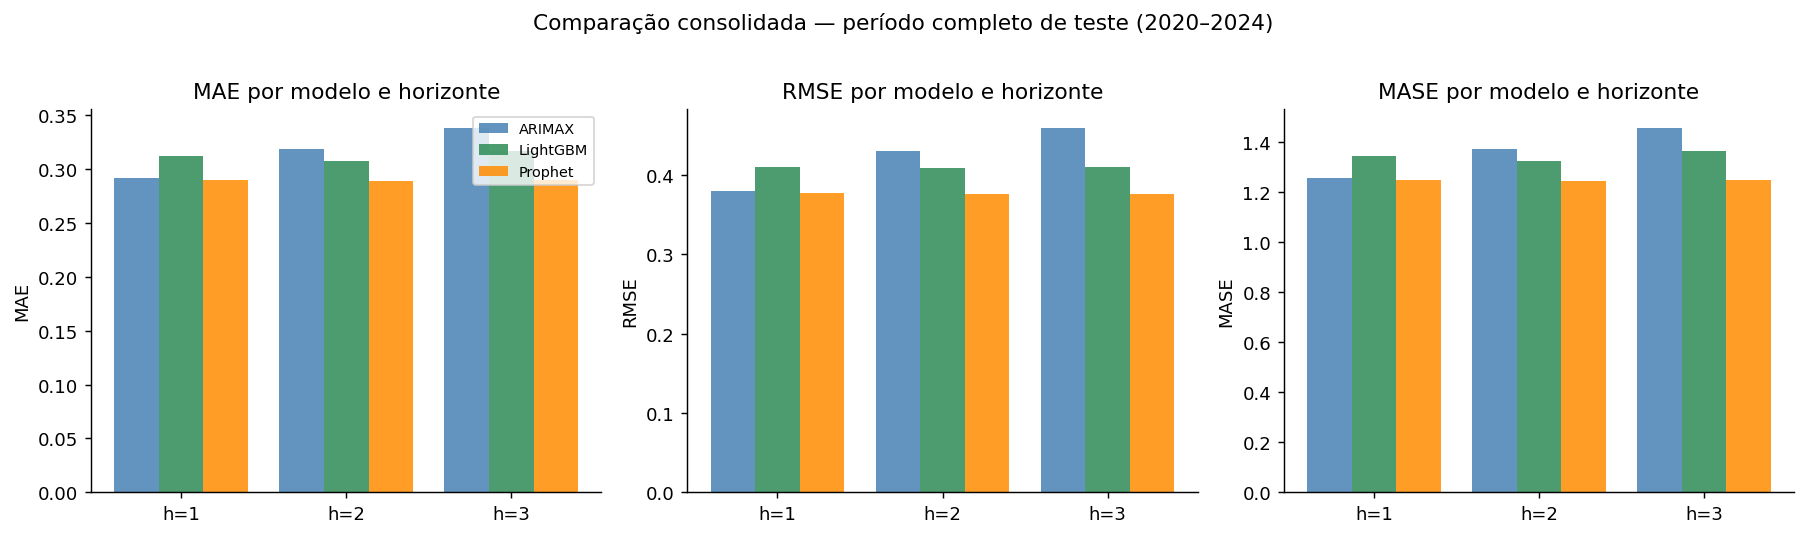

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

palette = {'ARIMAX': 'steelblue', 'LightGBM': 'seagreen', 'Prophet': 'darkorange'}

for ax, metric in zip(axes, ['MAE', 'RMSE', 'MASE']):
    piv = metrics_df.pivot(index='horizon', columns='model', values=metric)
    piv = piv[list(PATHS.keys())]

    x      = np.arange(len(piv.index))
    width  = 0.27

    for i, model in enumerate(piv.columns):
        ax.bar(x + (i - 1) * width, piv[model].values, width,
               color=palette[model], label=model, alpha=0.85)

    ax.set_xticks(x)
    ax.set_xticklabels([f'h={h}' for h in piv.index])
    ax.set_ylabel(metric)
    ax.set_title(f'{metric} por modelo e horizonte')
    if metric == 'MAE':
        ax.legend(fontsize=8)

fig.suptitle('Comparação consolidada — período completo de teste (2020–2024)', y=1.02)
plt.tight_layout()
plt.savefig('comparacao_metricas.png', dpi=150, bbox_inches='tight')
plt.show()

### 8.2. Realizado vs. previsto — três modelos lado a lado, h=1

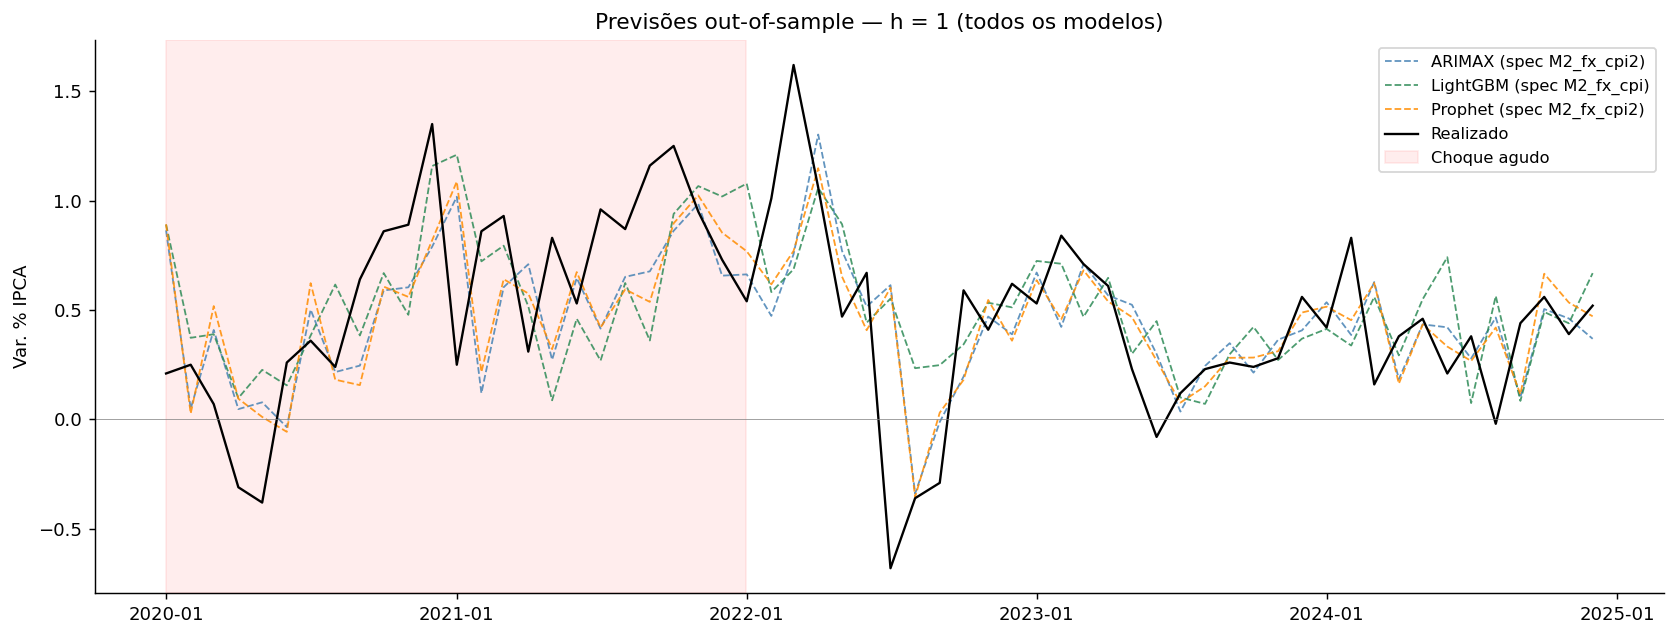

In [14]:
h = 1
fig, ax = plt.subplots(figsize=(13, 5))

for model in PATHS:
    d = get_preds(model, h)
    ax.plot(d['date'], d['predicted'],
            color=palette[model], linewidth=1.0, linestyle='--',
            label=f'{model} (spec {main_spec(model, h)})', alpha=0.85)

# Realizado — pega de qualquer modelo (todos têm o mesmo target)
d_act = get_preds('ARIMAX', h)
ax.plot(d_act['date'], d_act['actual'], color='black', linewidth=1.3, label='Realizado')

ax.axvspan(pd.Timestamp('2020-01-01'), pd.Timestamp('2021-12-31'),
           alpha=0.07, color='red', label='Choque agudo')
ax.axhline(0, color='gray', linewidth=0.4)
ax.set_title(f'Previsões out-of-sample — h = {h} (todos os modelos)')
ax.set_ylabel('Var. % IPCA')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.legend(fontsize=9, loc='upper right')

plt.tight_layout()
plt.savefig('comparacao_forecasts_h1.png', dpi=150, bbox_inches='tight')
plt.show()

### 8.3. Heatmap de p-valores DM par-a-par

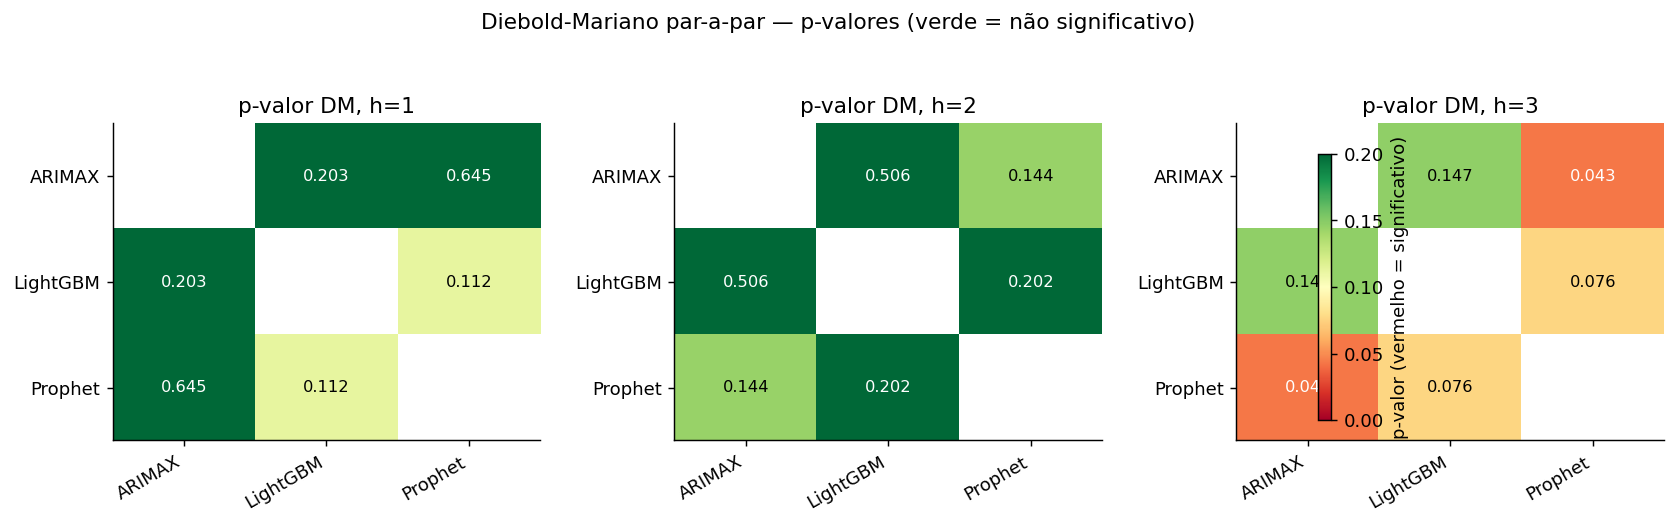

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

for ax, h in zip(axes, [1, 2, 3]):
    dm_h = dm_pairs_df[dm_pairs_df['horizon'] == h]
    if dm_h.empty:
        continue

    mat = pd.DataFrame(np.nan, index=models_list, columns=models_list, dtype=float)
    for _, r in dm_h.iterrows():
        mat.loc[r['model_a'], r['model_b']] = r['p_value']
        mat.loc[r['model_b'], r['model_a']] = r['p_value']

    im = ax.imshow(mat.values, cmap='RdYlGn', vmin=0, vmax=0.2, aspect='auto')
    ax.set_xticks(range(len(models_list)))
    ax.set_yticks(range(len(models_list)))
    ax.set_xticklabels(models_list, rotation=30, ha='right')
    ax.set_yticklabels(models_list)
    ax.set_title(f'p-valor DM, h={h}')

    for i, mi in enumerate(models_list):
        for j, mj in enumerate(models_list):
            val = mat.loc[mi, mj]
            if pd.notna(val):
                txt_color = 'white' if val < 0.05 or val > 0.15 else 'black'
                ax.text(j, i, f'{val:.3f}', ha='center', va='center',
                        color=txt_color, fontsize=9)

fig.colorbar(im, ax=axes, shrink=0.7, label='p-valor (vermelho = significativo)')
fig.suptitle('Diebold-Mariano par-a-par — p-valores (verde = não significativo)', y=1.05)
plt.tight_layout()
plt.savefig('comparacao_dm_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

### 8.4. MAE por regime — visualização de H2

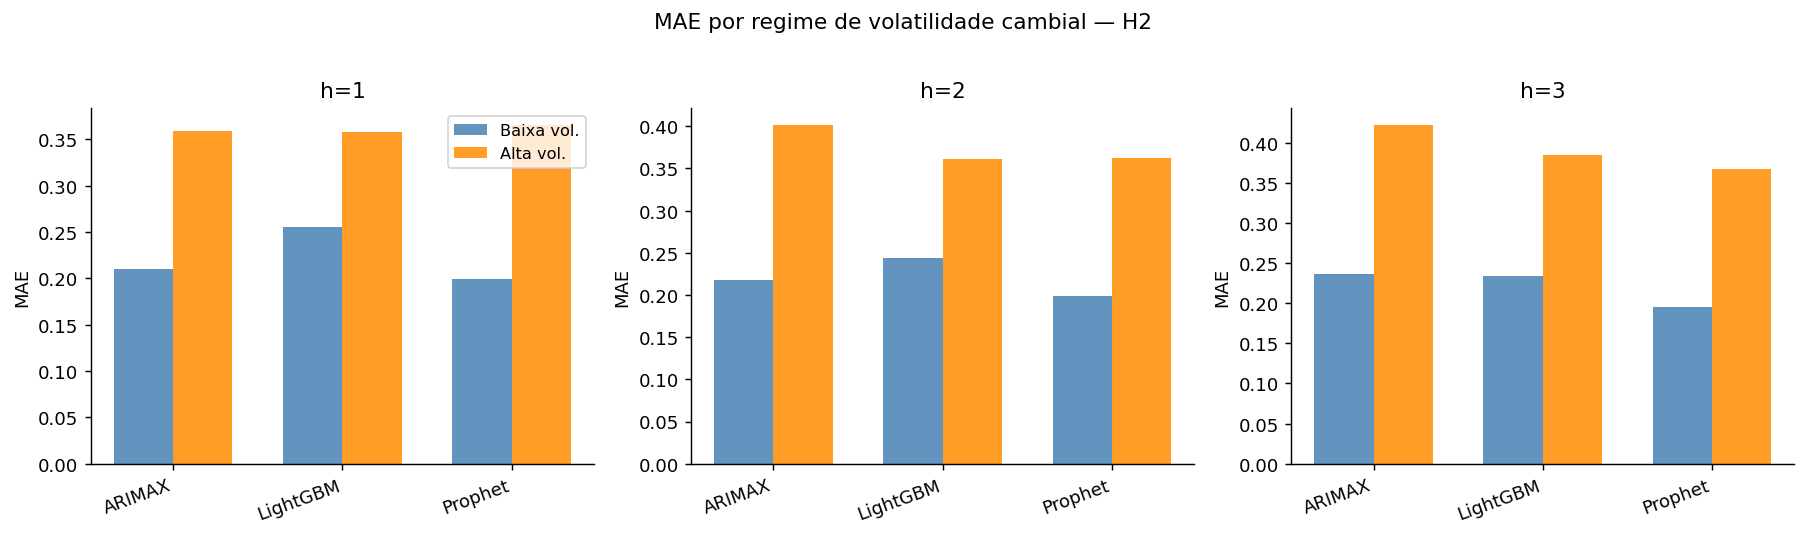

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, h in zip(axes, [1, 2, 3]):
    d_h = regime_df[regime_df['horizon'] == h]
    if d_h.empty:
        continue

    piv = d_h.pivot(index='model', columns='regime', values='MAE')[['baixa', 'alta']]
    piv = piv.reindex(list(PATHS.keys()))

    x     = np.arange(len(piv.index))
    width = 0.35

    ax.bar(x - width / 2, piv['baixa'], width, color='steelblue',  alpha=0.85, label='Baixa vol.')
    ax.bar(x + width / 2, piv['alta'],  width, color='darkorange', alpha=0.85, label='Alta vol.')

    ax.set_xticks(x)
    ax.set_xticklabels(piv.index, rotation=20, ha='right')
    ax.set_ylabel('MAE')
    ax.set_title(f'h={h}')
    if h == 1:
        ax.legend(fontsize=9)

fig.suptitle('MAE por regime de volatilidade cambial — H2', y=1.02)
plt.tight_layout()
plt.savefig('comparacao_regime_vol.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Síntese consolidada das três hipóteses


In [17]:
def best_model_by_h(metrics_df, horizon, metric='MAE'):
    d = metrics_df[metrics_df['horizon'] == horizon].sort_values(metric)
    return d.iloc[0]['model'], d.iloc[0][metric]


print('=' * 75)
print('SÍNTESE — TRÊS HIPÓTESES')
print('=' * 75)

print('\n[H1] Modelos de ML têm desempenho distinto do ARIMAX')
print('-' * 75)
print('Modelo com menor MAE por horizonte:')
for h in [1, 2, 3]:
    model, mae = best_model_by_h(metrics_df, h)
    print(f'  h={h}: {model:10} (MAE={mae:.4f})')

print('\nTestes DM par-a-par significativos a 5% (rejeita acurácia equivalente):')
sig_pairs = dm_pairs_df[dm_pairs_df['significant_5pct']]
if sig_pairs.empty:
    print('  Nenhum par mostra diferença significativa em nenhum horizonte.')
    print('  → H1 NÃO suportada: modelos têm acurácia estatisticamente equivalente.')
else:
    print(sig_pairs[['horizon', 'model_a', 'model_b', 'dm_stat', 'p_value']].to_string(index=False))

print('\n' + '-' * 75)
print('[H2] Vantagem do ML é maior em alta volatilidade cambial')
print('-' * 75)
print('Razão MAE alta/baixa por modelo e horizonte (>1 = pior em alta vol):')
print(h2_ratio.to_string())
print('''
→ Se LightGBM/Prophet têm razão menor que ARIMAX em alta volatilidade,
  H2 é suportada. Caso contrário, ML não tem vantagem em regimes turbulentos.
''')

print('-' * 75)
print('[H3] CPI EUA agrega ganho preditivo significativo (além do câmbio)')
print('-' * 75)
print(h3_df.pivot(index='model', columns='horizon', values='p_value').round(4).to_string())
sig_h3 = h3_df[h3_df['significant_5pct']]
if sig_h3.empty:
    print('\n→ H3 REJEITADA em todos os modelos e horizontes (nenhum p<0.05).')
    print('  CPI EUA condicionalmente redundante ao câmbio defasado.')
else:
    print('\nCasos com p<0.05:')
    print(sig_h3.to_string(index=False))

SÍNTESE — TRÊS HIPÓTESES

[H1] Modelos de ML têm desempenho distinto do ARIMAX
---------------------------------------------------------------------------
Modelo com menor MAE por horizonte:
  h=1: Prophet    (MAE=0.2903)
  h=2: Prophet    (MAE=0.2890)
  h=3: Prophet    (MAE=0.2902)

Testes DM par-a-par significativos a 5% (rejeita acurácia equivalente):
 horizon model_a model_b  dm_stat  p_value
       3  ARIMAX Prophet 2.020114 0.043372

---------------------------------------------------------------------------
[H2] Vantagem do ML é maior em alta volatilidade cambial
---------------------------------------------------------------------------
Razão MAE alta/baixa por modelo e horizonte (>1 = pior em alta vol):
regime              alta   baixa  ratio_alta_baixa
model    horizon                                  
ARIMAX   1        0.3587  0.2105            1.7041
         2        0.4013  0.2178            1.8423
         3        0.4218  0.2369            1.7805
LightGBM 1        0.357

## 10. Exportação do consolidado

In [18]:
metrics_df.to_csv('consolidado_metricas.csv',                     index=False)
subperiod_df.to_csv('consolidado_metricas_subperiodo.csv',        index=False)
regime_df.to_csv('consolidado_metricas_regime.csv',               index=False)
ratio.to_csv('consolidado_ratio_subperiodo.csv')
h2_ratio.to_csv('consolidado_h2_ratio_vol.csv')
dm_pairs_df.to_csv('consolidado_dm_par_a_par.csv',                index=False)
h3_df.to_csv('consolidado_h3_dm.csv',                             index=False)

print('Exportação concluída.')
print('\nArquivos gerados:')
for f in [
    'consolidado_metricas.csv',
    'consolidado_metricas_subperiodo.csv',
    'consolidado_metricas_regime.csv',
    'consolidado_ratio_subperiodo.csv',
    'consolidado_h2_ratio_vol.csv',
    'consolidado_dm_par_a_par.csv',
    'consolidado_h3_dm.csv',
    'comparacao_metricas.png',
    'comparacao_forecasts_h1.png',
    'comparacao_dm_heatmap.png',
    'comparacao_regime_vol.png',
]:
    print(f'  - {f}')

Exportação concluída.

Arquivos gerados:
  - consolidado_metricas.csv
  - consolidado_metricas_subperiodo.csv
  - consolidado_metricas_regime.csv
  - consolidado_ratio_subperiodo.csv
  - consolidado_h2_ratio_vol.csv
  - consolidado_dm_par_a_par.csv
  - consolidado_h3_dm.csv
  - comparacao_metricas.png
  - comparacao_forecasts_h1.png
  - comparacao_dm_heatmap.png
  - comparacao_regime_vol.png
